# Introducción al Proyecto: Predicción de Recuperación de Oro

## Contexto del Problema:
La empresa Zyfra desarrolla soluciones de eficiencia para la industria pesada y requiere de un modelo de Machine Learning para predecir la cantida de oro extraído, así como ayudar a la empresa a optimizar la producción.

## Objetivo del Proyecto:
Este proyecto tiene como objetivo predecir la cantidad de oro recuperado del mineral de oro en el proceso de purificación de Zyfra.

## Datos Disponibles:

- Tenemos 3 archivos CSV que contienen los datos de extracción y purificación: 
`gold_recovery_train-csv`, `gold_recovery_test.csv`y `gold_recovery_full_.csv`
- Los datos están indexados por fecha y hora de adquisición.
- Algunas características presentes en train no estan disponibles en test (porque se midieron más tarde).
- El conjunto de prueba no contiene los valores objetivo.

## Metodología: 

1. **Preparación de datos:** carga, verificación de la fórmula de recuperación, análisis de características faltantes y preprocesamiento
2. **Análisis de datos:** concentración de metales por etapa, comparación de distribuciones y detección de anomalías
3. **Construcción del modelo:** implementación de la métrica sMAPE, entrenamiento de varios modelos con validación cruzada y selección del mejor


## 1. Preparación de los datos

In [1]:
#Importar librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error , make_scorer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

### 1.1 Cargar y exploración de los datos

In [2]:
# Cargar los tres archivos CSV
train = pd.read_csv('/datasets/gold_recovery_train.csv', sep=',', encoding='utf-8', quotechar='"')
test = pd.read_csv('/datasets/gold_recovery_test.csv', sep=',', encoding='utf-8', quotechar='"')
full = pd.read_csv('/datasets/gold_recovery_full.csv', sep=',', encoding='utf-8', quotechar='"')

# Exploración inicial
print("Train info:")
print(train.info())
print("\nTest info:")
print(test.info())
print("\nFull info:")
print(full.info())

Train info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                16860 non-null  object 
 1   final.output.concentrate_ag                         16788 non-null  float64
 2   final.output.concentrate_pb                         16788 non-null  float64
 3   final.output.concentrate_sol                        16490 non-null  float64
 4   final.output.concentrate_au                         16789 non-null  float64
 5   final.output.recovery                               15339 non-null  float64
 6   final.output.tail_ag                                16794 non-null  float64
 7   final.output.tail_pb                                16677 non-null  float64
 8   final.output.tail_sol                               16715 non-nu

In [3]:
# Exploración de "Train"
print('Exploración del DataFrame de Entrenamiento (train)')
print(f"Forma del DataFrame: {train.shape}")
print("\nValores faltantes por columna (con porcentaje):")
missing_train = train.isnull().sum()
missing_train_percent = 100 * missing_train / len(train)
missing_train_table = pd.concat([missing_train, missing_train_percent], axis=1)
missing_train_table = missing_train_table.rename(columns = {0 : 'Valores Faltantes', 1 : '% del Total'})
missing_train_table = missing_train_table[missing_train_table.iloc[:,1] != 0].sort_values('% del Total', ascending=False).round(1)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

display(missing_train_table)
print("\nVista de las primeras 5 filas del DataFrame:")
display(train.head())
print("\nDescripción estadística del DataFrame:")
display(train.describe())
print(f"\nValores duplicados en el DataFrame: {train.duplicated().sum()}")

Exploración del DataFrame de Entrenamiento (train)
Forma del DataFrame: (16860, 87)

Valores faltantes por columna (con porcentaje):


,Valores Faltantes,% del Total
rougher.output.recovery,2573,15.3
rougher.output.tail_ag,2250,13.3
rougher.output.tail_au,2249,13.3
rougher.output.tail_sol,2249,13.3
secondary_cleaner.output.tail_sol,1986,11.8
rougher.input.floatbank11_xanthate,1904,11.3
final.output.recovery,1521,9.0
primary_cleaner.input.sulfate,1307,7.8
primary_cleaner.input.depressant,1262,7.5
rougher.calculation.au_pb_ratio,1242,7.4



Vista de las primeras 5 filas del DataFrame:


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,10.128295,7.25,0.988759,8.547551,10.389648,19.529297,34.174427,14.936526,2.534912,7.476074,2.106679,1549.775757,-498.912140,1551.434204,-516.403442,1549.873901,-498.666595,1554.367432,-493.428131,41885.707031,3481.779053,3520.337158,2.838687,6.100378,2.284912,523.546326,55.486599,36.808594,6.486150,11.986616,6.007990,11.836743,6.005818,11.500771,7.101074,28.029297,19.793808,87.107763,5.008018,0.508728,19.154297,1.170244,999.706909,-404.066986,1603.011353,-434.715027,1602.375000,-442.204468,1598.937256,-451.294128,1404.472046,-455.462982,1416.354980,-451.939636,14.500184,4.694824,8.764648,2.606185,25.853109,-498.526489,23.893660,-501.406281,23.961798,-495.262817,21.940409,-499.340973,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,125.629232,10.296251,7.25,1.002663,8.558743,10.


Descripción estadística del DataFrame:


,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
count,16788.000000,16788.000000,16490.000000,16789.000000,15339.000000,16794.000000,16677.000000,16715.000000,16794.000000,15553.000000,15598.000000,16860.000000,15875.000000,16778.000000,16502.000000,16224.000000,16778.000000,16777.000000,16761.000000,16579.000000,16777.000000,16820.000000,16827.000000,16820.000000,16833.000000,16822.000000,16833.000000,16821.000000,16833.000000,1.683300e+04,1.683300e+04,1.683300e+04,15618.000000,16778.000000,16632.000000,16347.000000,16443.000000,16568.000000,16777.000000,15816.000000,16514.000000,16237.000000,14956.000000,16778.000000,16778.000000,16698.000000,16778.000000,14287.000000,14610.000000,16778.000000,14611.000000,14611.000000,16807.000000,16807.000000,16807.000000,16807.000000,16807.000000,16814.000000,16802.000000,16809.000000,16257.000000,16809.000000,16802.000000,16802.000000,16776.000000,16764.000000,14874.000000,16778.000000,16497.000000,16751.000000,16705.000000,16748.000000,16763.000000,16747.000000,16752.000000,16750.000000,16731.000000,16747.000000,16768.000000,16767.000000,16775.000000,16775.000000,16775


Valores duplicados en el DataFrame: 0


In [4]:
# Exploración de "Test"
print('Exploración del DataFrame de Prueba (test)')
print(f"Forma del DataFrame: {test.shape}")
print("\nValores faltantes por columna (con porcentaje):")
missing_test = test.isnull().sum()
missing_test_percent = 100 * missing_test / len(test)
missing_test_table = pd.concat([missing_test, missing_test_percent], axis=1)
missing_test_table = missing_test_table.rename(columns = {0 : 'Valores Faltantes', 1 : '% del Total'})
missing_test_table = missing_test_table[missing_test_table.iloc[:,1] != 0].sort_values('% del Total', ascending=False).round(1)
display(missing_test_table)
print("\nVista de las primeras 5 filas del DataFrame:")
display(test.head())
print("\nDescripción estadística del DataFrame:")
display(test.describe())
print(f"\nValores duplicados en el DataFrame: {test.duplicated().sum()}")

Exploración del DataFrame de Prueba (test)
Forma del DataFrame: (5856, 53)

Valores faltantes por columna (con porcentaje):


,Valores Faltantes,% del Total
rougher.input.floatbank11_xanthate,353,6.0
primary_cleaner.input.sulfate,302,5.2
primary_cleaner.input.depressant,284,4.8
rougher.input.floatbank10_sulfate,257,4.4
primary_cleaner.input.xanthate,166,2.8
rougher.input.floatbank10_xanthate,123,2.1
rougher.input.feed_sol,67,1.1
rougher.input.floatbank11_sulfate,55,0.9
rougher.input.feed_rate,40,0.7
secondary_cleaner.state.floatbank3_a_air,34,0.6



Vista de las primeras 5 filas del DataFrame:


,date,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-09-01 00:59:59,210.800909,14.993118,8.080000,1.005021,1398.981301,-500.225577,1399.144926,-499.919735,1400.102998,-500.704369,1399.001695,-499.485144,13.128569,5.636710,489.793655,62.710452,42.022440,12.084103,16.922877,6.153479,16.867518,6.150709,1001.849317,-350.301265,1249.738612,-399.107531,1249.750520,-399.396730,1198.287855,-399.488594,999.472250,-399.530962,949.566189,-398.180807,24.938200,-500.490963,14.947607,-500.013837,20.018166,-450.395995,13.987058,-449.831513,12.023554,-497.795834,8.016656,-501.289139,7.946562,-432.317850,4.872511,-500.037437,26.705889,-499.709414
1,2016-09-01 01:59:59,215.392455,14.987471,8.080000,0.990469,1398.777912,-500.057435,1398.055362,-499.778182,1396.151033,-499.240168,1399.508091,-500.416324,13.036280,5.526065,490.104534,61.961163,41.187903,11.918977,17.002532,5.999043,16.996063,6.002315,998.690785,-350.425704,1248.395457,-399.946025,1249.514451,-399.630810,1200.506459,-399.942434,1000.002114,-399.491528,950.200009,-405.787514,24.923466,-499.813963,14.930873,-500.764452,19.988503,-450.114024,14.092981,-450.059163,12.058140,-498.695773,8.130979,-499.634209,7.958270,-525.839648,4.878850,-500.162375,25.019940,-499.819438
2,2016-09-01 02:59:59,215.259946,12.884934,7.786667,0.996043,1398.493666,-500.868360,1398.860436,-499.764529,1398.075709,-502.151509,1399.497088,-499.715479,13.138412,5.426561,489.617969,66.903807,42.546294,12.091332,16.992520,5.850632,16.982096,5.853594,998.516720,-349.783538,1247.440748,-400.264330,1248.207204,-401.074405,1199.770026,-400.790582,999.925519,-399.236999,950.320481,-400.864340,24.908732,-500.304035,14.996511,-500.993821,20.039689,-450.263164,14.077881,-449.660997,11.962366,-498.767484,8.096893,-500.827423,8.071056,-500.801673,4.905125,-499.828510,24.994862,-500.622559
3,2016-09-01 03:59:59,215.336236,12.006805,7.640000,0.863514,1399.618111,-498.863574,1397.440120,-499.211024,1400.129303,-498.355873,1401.065165,-501.038738,12.400507,5.114758,476.618130,59.865919,41.060195,12.181597,16.532144,5.801935,16.515277,5.803657,1000.276604,-350.172597,1251.322675,-398.655289,1250.493702,-399.746728,1199.398691,-397.50


Descripción estadística del DataFrame:


,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
count,5554.000000,5572.000000,5856.000000,5690.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5816.000000,5834.000000,5789.000000,5840.000000,5599.000000,5733.000000,5801.000000,5503.000000,5839.000000,5840.000000,5839.000000,5840.000000,5839.000000,5840.000000,5839.000000,5840.000000,5839.000000,5840.000000,5839.000000,5840.000000,5836.000000,5840.000000,5833.000000,5840.000000,5822.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000
mean,170.515243,8.482873,7.264651,1.321420,1481.990241,-509.057796,1486.908670,-511.743956,1468.495216,-509.741212,1486.398557,-510.723606,8.736170,3.552722,458.485472,55.937535,35.105834,8.700930,13.439933,6.169553,13.056047,6.423566,1016.294703,-404.977728,1270.598553,-482.154567,1253.495045,-480.945868,1169.675564,-482.152253,1018.386311,-476.551547,962.005375,-477.795380,25.479808,-513.714941,21.083475,-512.325717,24.345831,-519.417733,20.068079,-515.028316,15.636031,-516.266074,13.145702,-476.338907,12.308967,-512.208126,9.470986,-505.017827,16.678722,-512.351694
std,49.608602,3.353105,0.611526,0.693246,310.453166,61.339256,313.224286,67.139074,309.980748,62.671873,313.725248,65.417633,2.985805,1.326113,155.958272,22.724254,10.793249,2.803046,3.997715,1.673606,4.533948,1.120371,226.494775,100.953782,285.247715,55.399631,290.703157,53.759053,285.407244,54.967985,231.675756,67.002595,220.862435,68.342305,5.450424,62.448366,5.940017,63.376776,7.950733,73.968109,7.644391,60.457838,4.660835,62.756748,4.304086,105.549424,3.762827,58.864651,3.312471,68.785898,5.404514,69.919839
min,0.000103,0.000031,5.650000,0.000003,0.000000,-799.773788,0.000000,-800.029078,0.000000,-799.995127,0.000000,-799.838846,0.000000,0.000000,0.002986,0.046369,0.000000,0.000000,0.000154,0.000052,0.000014,0.000055,-0.123194,-657.949759,-0.821921,-650.349159,-0.282087,-650.000000,-1.047388,-648.390665,-2.076798,-650.152533,-2.593390,-650.034631,0.000000,-799.608557,0.000000,-798.467243,0.000000,-799.7


Valores duplicados en el DataFrame: 0


In [5]:
# Exploración de "Full"
print('Exploración del DataFrame Completo (full)')
print(f"Forma del DataFrame: {full.shape}")
print("\nValores faltantes por columna (con porcentaje):")
missing_full = full.isnull().sum()
missing_full_percent = 100 * missing_full / len(full)
missing_full_table = pd.concat([missing_full, missing_full_percent], axis=1)
missing_full_table = missing_full_table.rename(columns = {0 : 'Valores Faltantes', 1 : '% del Total'})
missing_full_table = missing_full_table[missing_full_table.iloc[:,1] != 0].sort_values('% del Total', ascending=False).round(1)
display(missing_full_table)
print("\nVista de las primeras 5 filas del DataFrame:")
display(full.head())
print("\nDescripción estadística del DataFrame:")
display(full.describe())
print(f"\nValores duplicados en el DataFrame: {full.duplicated().sum()}")

Exploración del DataFrame Completo (full)
Forma del DataFrame: (22716, 87)

Valores faltantes por columna (con porcentaje):


,Valores Faltantes,% del Total
rougher.output.recovery,3119,13.7
rougher.output.tail_ag,2737,12.0
rougher.output.tail_au,2736,12.0
rougher.output.tail_sol,2736,12.0
rougher.input.floatbank11_xanthate,2257,9.9
secondary_cleaner.output.tail_sol,2215,9.8
final.output.recovery,1963,8.6
rougher.calculation.au_pb_ratio,1627,7.2
primary_cleaner.input.sulfate,1609,7.1
primary_cleaner.input.depressant,1546,6.8



Vista de las primeras 5 filas del DataFrame:


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,10.128295,7.25,0.988759,8.547551,10.389648,19.529297,34.174427,14.936526,2.534912,7.476074,2.106679,1549.775757,-498.912140,1551.434204,-516.403442,1549.873901,-498.666595,1554.367432,-493.428131,41885.707031,3481.779053,3520.337158,2.838687,6.100378,2.284912,523.546326,55.486599,36.808594,6.486150,11.986616,6.007990,11.836743,6.005818,11.500771,7.101074,28.029297,19.793808,87.107763,5.008018,0.508728,19.154297,1.170244,999.706909,-404.066986,1603.011353,-434.715027,1602.375000,-442.204468,1598.937256,-451.294128,1404.472046,-455.462982,1416.354980,-451.939636,14.500184,4.694824,8.764648,2.606185,25.853109,-498.526489,23.893660,-501.406281,23.961798,-495.262817,21.940409,-499.340973,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,125.629232,10.296251,7.25,1.002663,8.558743,10.


Descripción estadística del DataFrame:


,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
count,22627.000000,22629.000000,22331.000000,22630.000000,20753.000000,22633.000000,22516.000000,22445.000000,22635.000000,21107.000000,21170.000000,22716.000000,21565.000000,22618.000000,22268.000000,21918.000000,22618.000000,22614.000000,22594.000000,22365.000000,22617.000000,22660.000000,22667.000000,22660.000000,22673.000000,22662.000000,22673.000000,22661.000000,22673.000000,2.267200e+04,2.267200e+04,2.267200e+04,21089.000000,22618.000000,22472.000000,22163.000000,22277.000000,22357.000000,22617.000000,21415.000000,22247.000000,22038.000000,20459.000000,22618.000000,22618.000000,22526.000000,22618.000000,19597.000000,19979.000000,22618.000000,19980.000000,19980.000000,22646.000000,22647.000000,22646.000000,22647.000000,22646.000000,22654.000000,22641.000000,22649.000000,22096.000000,22649.000000,22641.000000,22642.000000,22616.000000,22600.000000,20501.000000,22618.000000,22333.000000,22591.000000,22538.000000,22588.000000,22585.000000,22587.000000,22592.000000,22590.000000,22571.000000,22587.000000,22608.000000,22607.000000,22615.000000,22615.000000,22615


Valores duplicados en el DataFrame: 0


### Observaciones iniciales

**Exploración del DataFrame de Entrenamiento (train)**
- **Forma del DataFrame:** Contiene 16860 filas y 87 columnas.
- **Información general:** La mayoría de las columnas son de tipo float64, con una columna date de tipo object. Se observan varias columnas con valores no nulos significativamente menores al total de filas, indicando presencia de valores faltantes.
- **Valores Faltantes**: Algunas de las columnas con más valores faltantes son rougher.output.recovery (15.3%), rougher.output.tail_ag (13.3%), rougher.output.tail_au (13.3%), rougher.output.tail_sol (13.3%), y secondary_cleaner.output.tail_sol (11.8%).
- **Duplicados:** Se encontraron 0 filas duplicadas.

**Exploración del DataFrame de Prueba (test)**
- **Forma del DataFrame:** Contiene 5856 filas y 53 columnas. Es importante notar que tiene menos columnas que el DataFrame de entrenamiento.
- **Información general:** Similar al conjunto de entrenamiento, la mayoría de las columnas son float64 y date es object. También presenta valores nulos.
- **Valores Faltantes:** Las columnas con mayor porcentaje de valores faltantes incluyen rougher.input.floatbank11_xanthate (6.0%), primary_cleaner.input.sulfate (5.2%) y primary_cleaner.input.depressant (4.8%).
- **Duplicados:** Se encontraron 0 filas duplicadas.

**Exploración del DataFrame Completo (full)**
- **Forma del DataFrame:** Contiene 22716 filas y 87 columnas, lo cual es la suma de train y test en cuanto a filas y las mismas columnas que train.
- **Información general:** Consistente con los otros dos DataFrames, predomina float64 y la columna date es object.
- **Valores Faltantes:** Las columnas con más valores faltantes son rougher.output.recovery (13.7%), rougher.output.tail_ag (12.0%), rougher.output.tail_au (12.0%), rougher.output.tail_sol (12.0%) y rougher.input.floatbank11_xanthate (9.9%).
- **Duplicados:** Se encontraron 0 filas duplicadas.

### 1.2. Verificación del cálculo de recuperación (rougher.output.recovery)

En esta sección verificaremos que la fórmula de recuperación es correcta
comparando el valor calculado con el valor real del dataset.


In [6]:
# Calcular rougher.output.recovery con la fórmula

# Definir variables para calcular la recuperación
C = train['rougher.output.concentrate_au']
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']

# Calcular la recuperación 
recovery_calculated = (C * (F - T)) / (F* (C - T)) * 100


# Crear DataFrame de comparación 
recovery_comparison = pd.DataFrame({
    'calculated': recovery_calculated,
    'actual': train['rougher.output.recovery']
})

# Eliminamos filas donde 'actual' es NaN o donde 'calculated' es NaN
recovery_comparison = recovery_comparison.dropna()

print("Primeras 5 filas de la comparación de recuperación:")
display(recovery_comparison.head())

Primeras 5 filas de la comparación de recuperación:


,calculated,actual
0,87.107763,87.107763
1,86.843261,86.843261
2,86.842308,86.842308
3,87.226430,87.226430
4,86.688794,86.688794


In [7]:
# Calcular el EAM entre el valor calculado y el valor real
mae = mean_absolute_error(recovery_comparison['actual'], recovery_comparison['calculated'])
print(f"MAE entre la recuperación calculada y la real: {mae}")

MAE entre la recuperación calculada y la real: 9.303415616264301e-15


### Observaciones del cálculo de recuperación
- **EAM obtenido:** `9.30 e-15`
- **Conclusión:** El MAE es extremadamente bajo, lo que indica que el cálculo de la recuperación usando la fórmula proporcionada coincide casi perfectamente con los valores existentes en el dataset. Esto confirma que la fórmula es correcta y que podemos proceder con confianza.

### 1.3. Características no disponibles en el conjunto de prueba
Analizaremos qué columnas están presentes en train pero no en test.

In [8]:
#Obtener columnas y convertirlas a set
train_cols = set(train.columns)
test_cols = set(test.columns)

#encontrar la diferencia entre ambos conjuntos
missing_in_test = list(train_cols - test_cols)

print(f"Número de columnas en el conjunto de entrenamiento: {len(train_cols)}")
print(f"Número de columnas en el conjunto de prueba: {len(test_cols)}")
print(f"Número de columnas presentes en train pero no en test: {len(missing_in_test)}")
print("\nColumnas presentes en train pero ausentes en test:")
for col in sorted(missing_in_test):
    print(f"- {col}")

Número de columnas en el conjunto de entrenamiento: 87
Número de columnas en el conjunto de prueba: 53
Número de columnas presentes en train pero no en test: 34

Columnas presentes en train pero ausentes en test:
- final.output.concentrate_ag
- final.output.concentrate_au
- final.output.concentrate_pb
- final.output.concentrate_sol
- final.output.recovery
- final.output.tail_ag
- final.output.tail_au
- final.output.tail_pb
- final.output.tail_sol
- primary_cleaner.output.concentrate_ag
- primary_cleaner.output.concentrate_au
- primary_cleaner.output.concentrate_pb
- primary_cleaner.output.concentrate_sol
- primary_cleaner.output.tail_ag
- primary_cleaner.output.tail_au
- primary_cleaner.output.tail_pb
- primary_cleaner.output.tail_sol
- rougher.calculation.au_pb_ratio
- rougher.calculation.floatbank10_sulfate_to_au_feed
- rougher.calculation.floatbank11_sulfate_to_au_feed
- rougher.calculation.sulfate_to_au_concentrate
- rougher.output.concentrate_ag
- rougher.output.concentrate_au
- r

In [9]:
# Verificar tipos de parámetros ausentes en test
print("\nTipo de los parámetros ausentes en test:")
for col in sorted(missing_in_test):
    print(f"- {col}: {train[col].dtype}")


Tipo de los parámetros ausentes en test:
- final.output.concentrate_ag: float64
- final.output.concentrate_au: float64
- final.output.concentrate_pb: float64
- final.output.concentrate_sol: float64
- final.output.recovery: float64
- final.output.tail_ag: float64
- final.output.tail_au: float64
- final.output.tail_pb: float64
- final.output.tail_sol: float64
- primary_cleaner.output.concentrate_ag: float64
- primary_cleaner.output.concentrate_au: float64
- primary_cleaner.output.concentrate_pb: float64
- primary_cleaner.output.concentrate_sol: float64
- primary_cleaner.output.tail_ag: float64
- primary_cleaner.output.tail_au: float64
- primary_cleaner.output.tail_pb: float64
- primary_cleaner.output.tail_sol: float64
- rougher.calculation.au_pb_ratio: float64
- rougher.calculation.floatbank10_sulfate_to_au_feed: float64
- rougher.calculation.floatbank11_sulfate_to_au_feed: float64
- rougher.calculation.sulfate_to_au_concentrate: float64
- rougher.output.concentrate_ag: float64
- roughe

### Observaciones 1.3.
- **Características ausentes:** Después de comparar los conjuntos de datos de entrenamiento y prueba, se identificaron `34` columnas presentes en el entrenamiento pero ausentes en el conjunto de prueba.
- **Tipo de parámetros ausentes:** La mayoría de estas columnas ausentes corresponden a `output` y `calculation` de las diferentes etapas del proceso (`rougher`, `primary_cleaner`, `final`). Todas ellas son de tipo `float64`. Esto es esperado, ya que los datos de prueba suelen simular un escenario de producción donde algunas salidas y cálculos aún no están disponibles o no son relevantes para la predicción.

### 1.4. Preprocesamiento de datos
Trataremos los valores nulos y realizaremos las transformaciones necesarias.
- Primero imputaremos los valores nulos de cada data set con la mediana de cada columna.
- Después procesaremos la columna date de cada DataFrame para convertirla a datetime y la estableceremos como índice para ordenar los datos temporalmente

In [10]:
# Imputar valores nulos con la mediana
train = train.fillna(train.median())
test = test.fillna(test.median())
full = full.fillna(full.median())

print("Valores nulos tratados en train, test y full.")
print(f"NaNs restantes en train: {train.isnull().sum().sum()}")
print(f"NaNs restantes en test: {test.isnull().sum().sum()}")
print(f"NaNs restantes en full: {full.isnull().sum().sum()}")


Valores nulos tratados en train, test y full.
NaNs restantes en train: 0
NaNs restantes en test: 0
NaNs restantes en full: 0


In [11]:
# Procesar la columna 'dat"columna 'date' para cada DataFrame

#Train
if 'date' in train.columns:
    train['date'] = pd.to_datetime(train['date'])
    train = train.set_index('date').sort_index()
    print ("Columna 'date' convertida a índice y ordenada para train")
else: 
    print("La columna 'date' ya es el indice.")

#Test
if 'date' in test.columns:
    test['date'] = pd.to_datetime(test['date'])
    test = test.set_index('date').sort_index()
    print("Columna 'date' convertida a índice y ordenada para test.")
else:
    print("La columna 'date'  ya es el índice.")

#Full
if 'date' in full.columns:
    full['date'] = pd.to_datetime(full['date'])
    full = full.set_index('date').sort_index()
    print("Columna 'date' convertida a índice y ordenada para full.")
else:
    print("La columna 'date' ya es el índice.")



Columna 'date' convertida a índice y ordenada para train
Columna 'date' convertida a índice y ordenada para test.
Columna 'date' convertida a índice y ordenada para full.


In [12]:
# Visualizar los Data Frame después de la conversión
display(train.head())
display(test.head())
display(full.head())

,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,10.128295,7.25,0.988759,8.547551,10.389648,19.529297,34.174427,14.936526,2.534912,7.476074,2.106679,1549.775757,-498.912140,1551.434204,-516.403442,1549.873901,-498.666595,1554.367432,-493.428131,41885.707031,3481.779053,3520.337158,2.838687,6.100378,2.284912,523.546326,55.486599,36.808594,6.486150,11.986616,6.007990,11.836743,6.005818,11.500771,7.101074,28.029297,19.793808,87.107763,5.008018,0.508728,19.154297,1.170244,999.706909,-404.066986,1603.011353,-434.715027,1602.375000,-442.204468,1598.937256,-451.294128,1404.472046,-455.462982,1416.354980,-451.939636,14.500184,4.694824,8.764648,2.606185,25.853109,-498.526489,23.893660,-501.406281,23.961798,-495.262817,21.940409,-499.340973,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.

,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2016-09-01 00:59:59,210.800909,14.993118,8.080000,1.005021,1398.981301,-500.225577,1399.144926,-499.919735,1400.102998,-500.704369,1399.001695,-499.485144,13.128569,5.636710,489.793655,62.710452,42.022440,12.084103,16.922877,6.153479,16.867518,6.150709,1001.849317,-350.301265,1249.738612,-399.107531,1249.750520,-399.396730,1198.287855,-399.488594,999.472250,-399.530962,949.566189,-398.180807,24.938200,-500.490963,14.947607,-500.013837,20.018166,-450.395995,13.987058,-449.831513,12.023554,-497.795834,8.016656,-501.289139,7.946562,-432.317850,4.872511,-500.037437,26.705889,-499.709414
2016-09-01 01:59:59,215.392455,14.987471,8.080000,0.990469,1398.777912,-500.057435,1398.055362,-499.778182,1396.151033,-499.240168,1399.508091,-500.416324,13.036280,5.526065,490.104534,61.961163,41.187903,11.918977,17.002532,5.999043,16.996063,6.002315,998.690785,-350.425704,1248.395457,-399.946025,1249.514451,-399.630810,1200.506459,-399.942434,1000.002114,-399.491528,950.200009,-405.787514,24.923466,-499.813963,14.930873,-500.764452,19.988503,-450.114024,14.092981,-450.059163,12.058140,-498.695773,8.130979,-499.634209,7.958270,-525.839648,4.878850,-500.162375,25.019940,-499.819438
2016-09-01 02:59:59,215.259946,12.884934,7.786667,0.996043,1398.493666,-500.868360,1398.860436,-499.764529,1398.075709,-502.151509,1399.497088,-499.715479,13.138412,5.426561,489.617969,66.903807,42.546294,12.091332,16.992520,5.850632,16.982096,5.853594,998.516720,-349.783538,1247.440748,-400.264330,1248.207204,-401.074405,1199.770026,-400.790582,999.925519,-399.236999,950.320481,-400.864340,24.908732,-500.304035,14.996511,-500.993821,20.039689,-450.263164,14.077881,-449.660997,11.962366,-498.767484,8.096893,-500.827423,8.071056,-500.801673,4.905125,-499.828510,24.994862,-500.622559
2016-09-01 03:59:59,215.336236,12.006805,7.640000,0.863514,1399.618111,-498.863574,1397.440120,-499.211024,1400.129303,-498.355873,1401.065165,-501.038738,12.400507,5.114758,476.618130,59.865919,41.060195,12.181597,16.532144,5.801935,16.515277,5.803657,1000.276604,-350.172597,1251.322675,-398.655289

,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,10.128295,7.25,0.988759,8.547551,10.389648,19.529297,34.174427,14.936526,2.534912,7.476074,2.106679,1549.775757,-498.912140,1551.434204,-516.403442,1549.873901,-498.666595,1554.367432,-493.428131,41885.707031,3481.779053,3520.337158,2.838687,6.100378,2.284912,523.546326,55.486599,36.808594,6.486150,11.986616,6.007990,11.836743,6.005818,11.500771,7.101074,28.029297,19.793808,87.107763,5.008018,0.508728,19.154297,1.170244,999.706909,-404.066986,1603.011353,-434.715027,1602.375000,-442.204468,1598.937256,-451.294128,1404.472046,-455.462982,1416.354980,-451.939636,14.500184,4.694824,8.764648,2.606185,25.853109,-498.526489,23.893660,-501.406281,23.961798,-495.262817,21.940409,-499.340973,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.

### Observaciones 1.4.
- **Estrategia usada para valores nulos:** Se utilizó una estrategia de imputación por la mediana de cada columna ya que esta estrategia es robusta a los valores atípicos (outliers) y nos proporciona un valor central para cada característica. Aunque en series temporales el forward fill podría ser más apropiado, la mediana ofrece una imputación estable y sin riesgo de propagar errores ante la gran cantidad de valores nulos consecutivos que existen en los datasets originales.
- **Resultado del tratamiento de nulos:** Después de aplicar la estrategia, **no quedan valores nulos** en ninguno de los DataFrames (`train`, `test`, `full`).
- **Transformaciones adicionales:** La columna `date` se convirtió a tipo `datetime` y se estableció como índice para todos los DataFrames, asegurando la correcta manipulación de datos de series temporales.

### 2.1. Concentración de metales por etapa de purificación (Au, Ag, Pb)
Analizaremos y vusualizaremos cómo cambian las concentraciónes promedio de cada metal (oro, plata y plomo) a lo largo
de las difeerentes etapas del proceso de purificación.

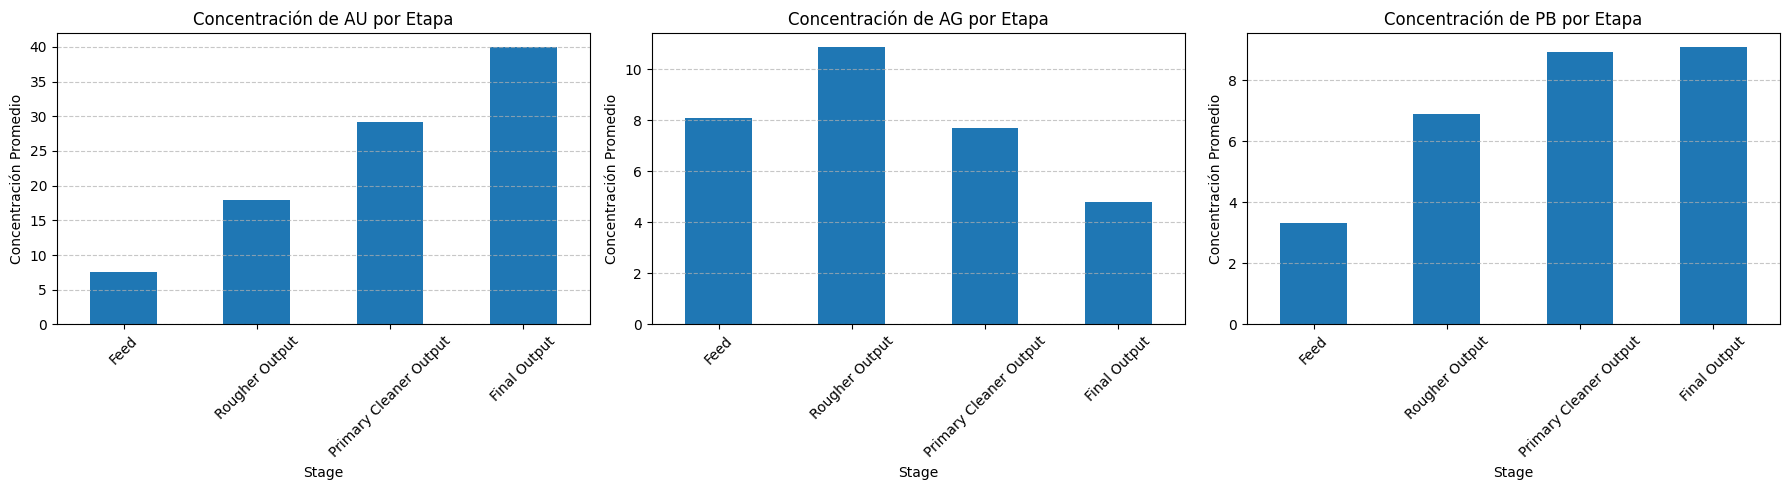

Concentración promedio de metales por etapa:
--- AU ---
  Feed: 7.57
  Rougher Output: 17.89
  Primary Cleaner Output: 29.23
  Final Output: 40.02
--- AG ---
  Feed: 8.07
  Rougher Output: 10.88
  Primary Cleaner Output: 7.69
  Final Output: 4.78
--- PB ---
  Feed: 3.31
  Rougher Output: 6.90
  Primary Cleaner Output: 8.94
  Final Output: 9.10


In [13]:
# Graficar distribución de concentración de Au, Ag y Pb en cada etapa: feed, rougher, cleaner, final

# Definir las etapas y los metales
stages = ['rougher.input.feed', 'rougher.output', 'primary_cleaner.output', 'final.output']
metals = ['au', 'ag', 'pb']

# Crear subplots para cada metal
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

for i, metal in enumerate(metals):
    concentrations = []
    for stage in stages:
        # Construir el nombre de la columna para cada etapa y metal
        # La etapa inicial 'feed' no tiene .output, solo .input.feed
        if stage == 'rougher.input.feed':
            col_name = f'{stage}_{metal}'
        else:
            col_name = f'{stage}.concentrate_{metal}'

        # Nos aseguramos de que la columna exista antes de intentar calcular la media
        if col_name in full.columns:
            concentrations.append(full[col_name].mean())
        else:
            concentrations.append(np.nan) # Si la columna no existe, añadir NaN

    # Crear un DataFrame para graficar
    df_plot = pd.DataFrame({
        'Stage': ['Feed', 'Rougher Output', 'Primary Cleaner Output', 'Final Output'],
        'Concentration': concentrations
    })

    # Graficar la concentración
    df_plot.plot(kind='bar', x='Stage', y='Concentration', ax=axes[i], legend=False)
    axes[i].set_title(f'Concentración de {metal.upper()} por Etapa')
    axes[i].set_ylabel('Concentración Promedio')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("Concentración promedio de metales por etapa:")
for metal in metals:
    print(f"--- {metal.upper()} ---")
    for stage in stages:
        if stage == 'rougher.input.feed':
            col_name = f'{stage}_{metal}'
            stage_label = 'Feed'
        else:
            col_name = f'{stage}.concentrate_{metal}'
            stage_label = stage.replace('.output', '').replace('_', ' ').title() + ' Output'

        if col_name in full.columns:
            print(f"  {stage_label}: {full[col_name].mean():.2f}")
        else:
            print(f"  {stage_label}: Columna no encontrada")

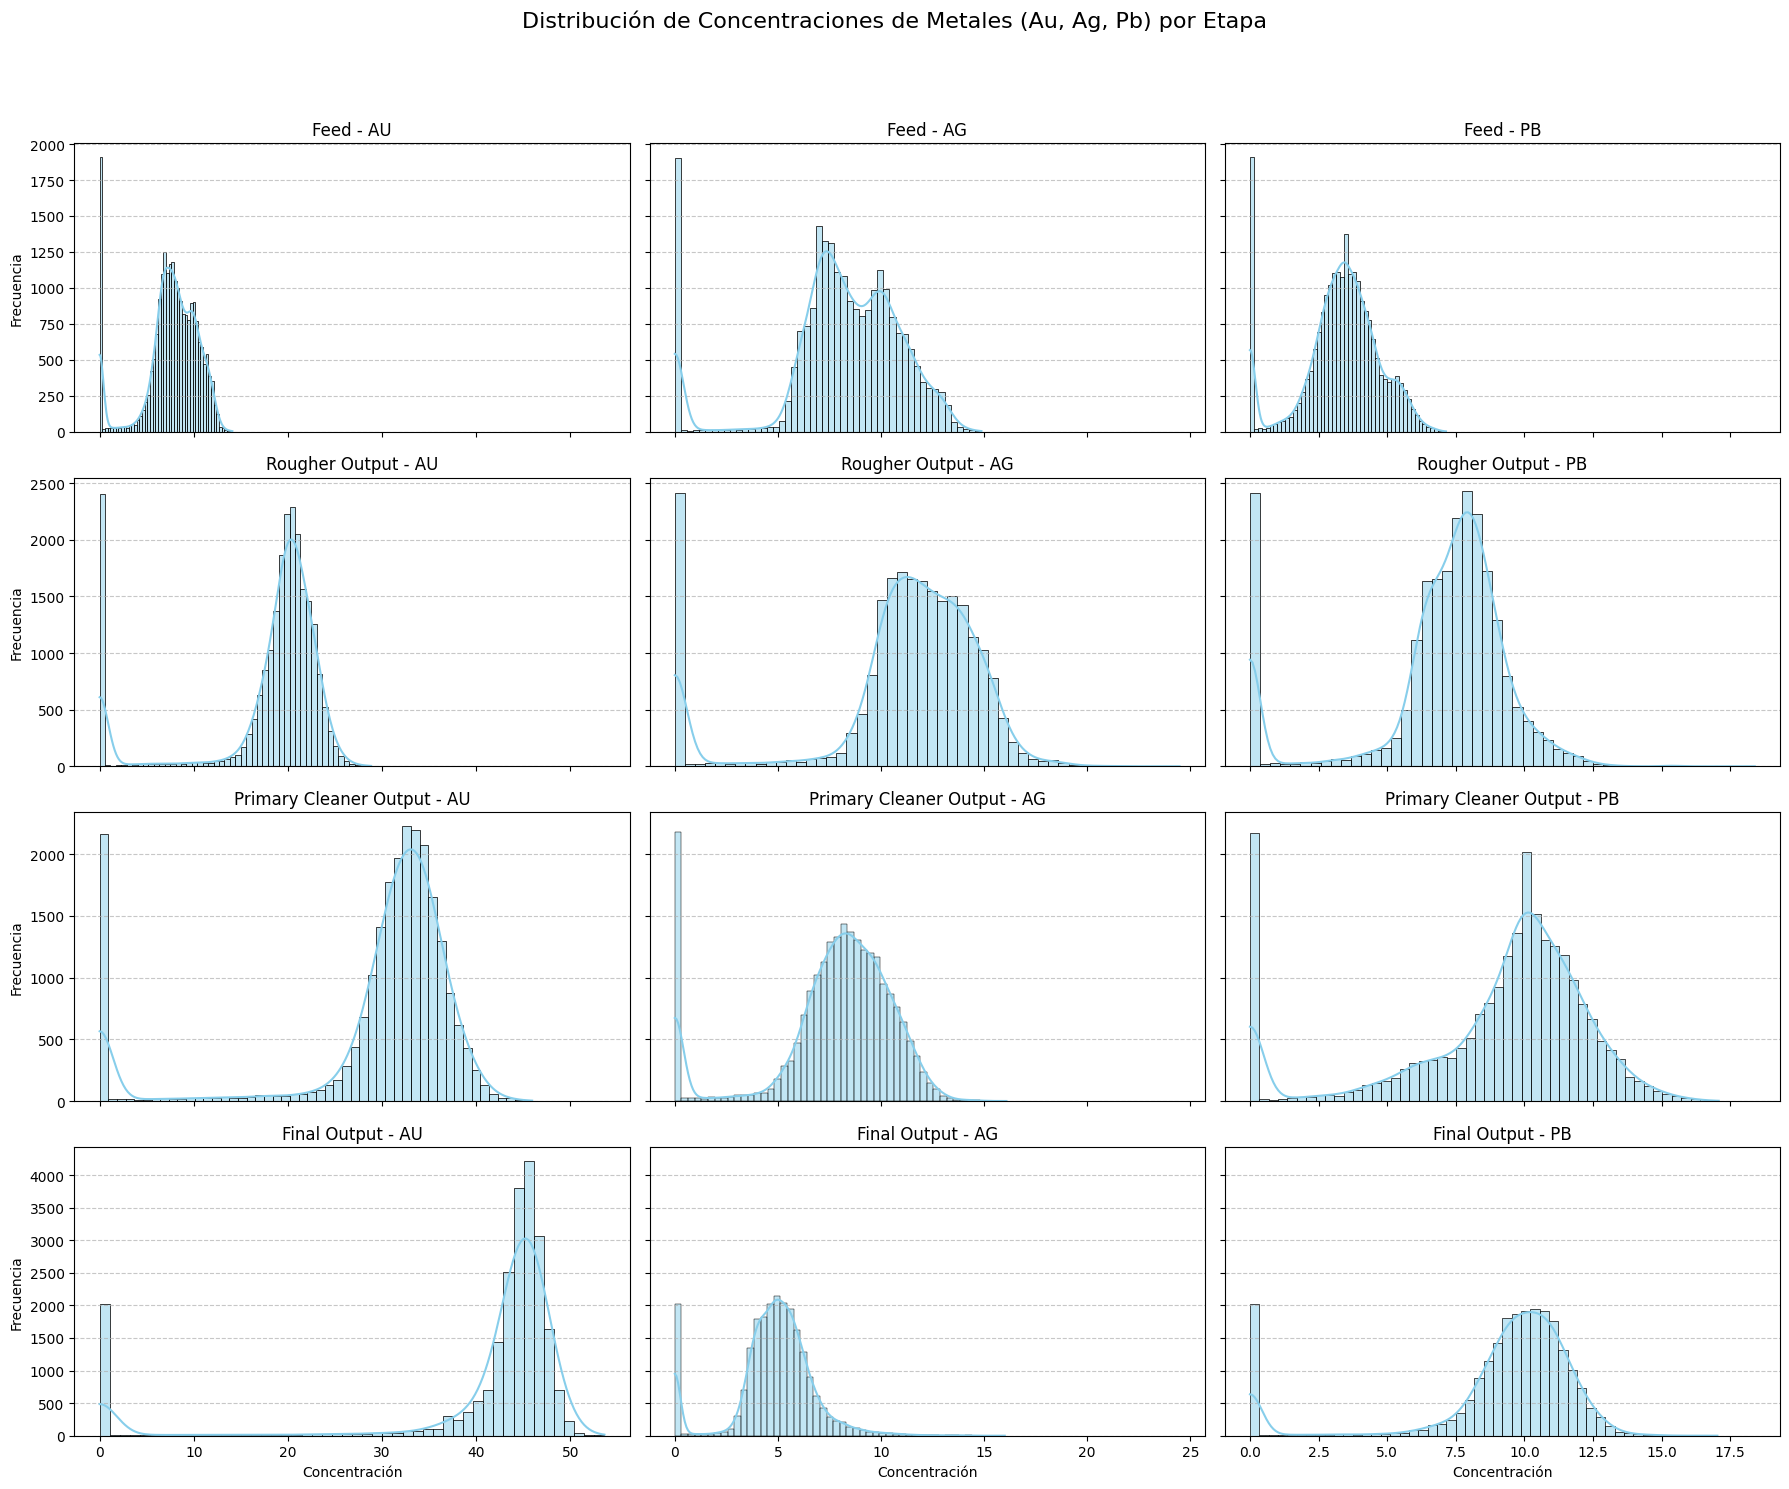

In [14]:
# Distribución d econcentraciones de Metales por Etapa (Historgramas)

# Definir las etapas y los metales
stages = [
    ('rougher.input.feed', 'Feed'),
    ('rougher.output', 'Rougher Output'),
    ('primary_cleaner.output', 'Primary Cleaner Output'),
    ('final.output', 'Final Output')
]
metals = ['au', 'ag', 'pb']

# Crear subplots para cada metal y etapa
# El número de filas será el número de etapas, el número de columnas el número de metales
fig, axes = plt.subplots(len(stages), len(metals), figsize=(18, 15), sharex='col', sharey='row')
fig.suptitle('Distribución de Concentraciones de Metales (Au, Ag, Pb) por Etapa', fontsize=16, y=1.02)

for i, (stage_prefix, stage_label) in enumerate(stages):
    for j, metal in enumerate(metals):
        ax = axes[i, j]

        # Construir el nombre de la columna para cada etapa y metal
        if stage_prefix == 'rougher.input.feed':
            col_name = f'{stage_prefix}_{metal}'
        else:
            col_name = f'{stage_prefix}.concentrate_{metal}'

        if col_name in full.columns:
            sns.histplot(full[col_name].dropna(), kde=True, ax=ax, bins=50, color='skyblue')
            ax.set_title(f'{stage_label} - {metal.upper()}')
            ax.set_xlabel('Concentración')
            ax.set_ylabel('Frecuencia')
            ax.grid(axis='y', linestyle='--', alpha=0.7)
        else:
            ax.set_title(f'{stage_label} - {metal.upper()} (Columna no encontrada)')
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.text(0.5, 0.5, 'Datos no disponibles', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) 
plt.show()

#### Observaciones 2.1
- **Comportamiento del Au (Oro):** La concentración de oro aumenta significativamente en cada etapa del proceso, desde la alimentación (`Feed`) hasta el `Final Output`. Pasa de un promedio de **7.57** en `Feed` a **40.02** en `Final Output`, lo cual es el objetivo del proceso. En los histogramas, observamos un claro desplazamiento de la distribución hacia concentraciones más altas a medida que avanza el proceso. En la etapa `Feed`, la distribución es más amplia y baja, indicando menor concentración. En `Final Output`, la distribución es estrecha y centrada en valores altos (alrededor de 40), lo que confirma una purificación efectiva y el éxito en concentrar el oro.
- **Comportamiento del Ag (Plata):** La concentración de plata aumenta inicialmente en la etapa `Rougher Output` (de **8.07** a **10.88**), pero luego disminuye drásticamente en las etapas de limpieza (`Primary Cleaner Output`: **7.69** y `Final Output`: **4.78**). Esto indica que la plata se separa eficientemente durante la purificación. En los histogramas obsrvamos que la concentración de plata aumenta después de la flotación (Rougher Output), pero luego disminuye progresivamente en las etapas de limpieza (Primary Cleaner Output y Final Output). Esto indica que el proceso está diseñado para eliminar eficientemente la plata a medida que se concentra el oro.
- **Comportamiento del Pb (Plomo):** La concentración de plomo muestra un aumento constante en todas las etapas, de **3.31** en `Feed` a **9.10** en `Final Output`. Aunque se concentra, su incremento es menos pronunciado que el del oro. Los histogramas confirman cómo  el plomo tiende a concentrarse a lo largo de las etapas, mostrando un aumento general en sus distribuciones, similar al oro en las etapas iniciales, pero con una concentración final menor. La distribución en `Final Output` sigue siendo alta, lo que sugiere que el plomo también se concentra hasta cierto punto junto con el oro, aunque con algunas anomalías con una concentración muy cercana a cero.

### 2.2 Comparación del tamaño de partículas entre train y test
Verificaremos que la distribución del tamaño de partículas sea similar en ambos conjuntos. Esto es muy importante porque si las distribuciones son muy diferentes, el modelo no funcionará bien. Las columnas relevantes son las de tamaño de partícula `feed_size`, y en el dataset tenemos dos: `rougher.input.feed_size`y `primary_cleaner.input.feed_size`. Para comparar estas distrubiciones utilizaremos KDE de cada columna.

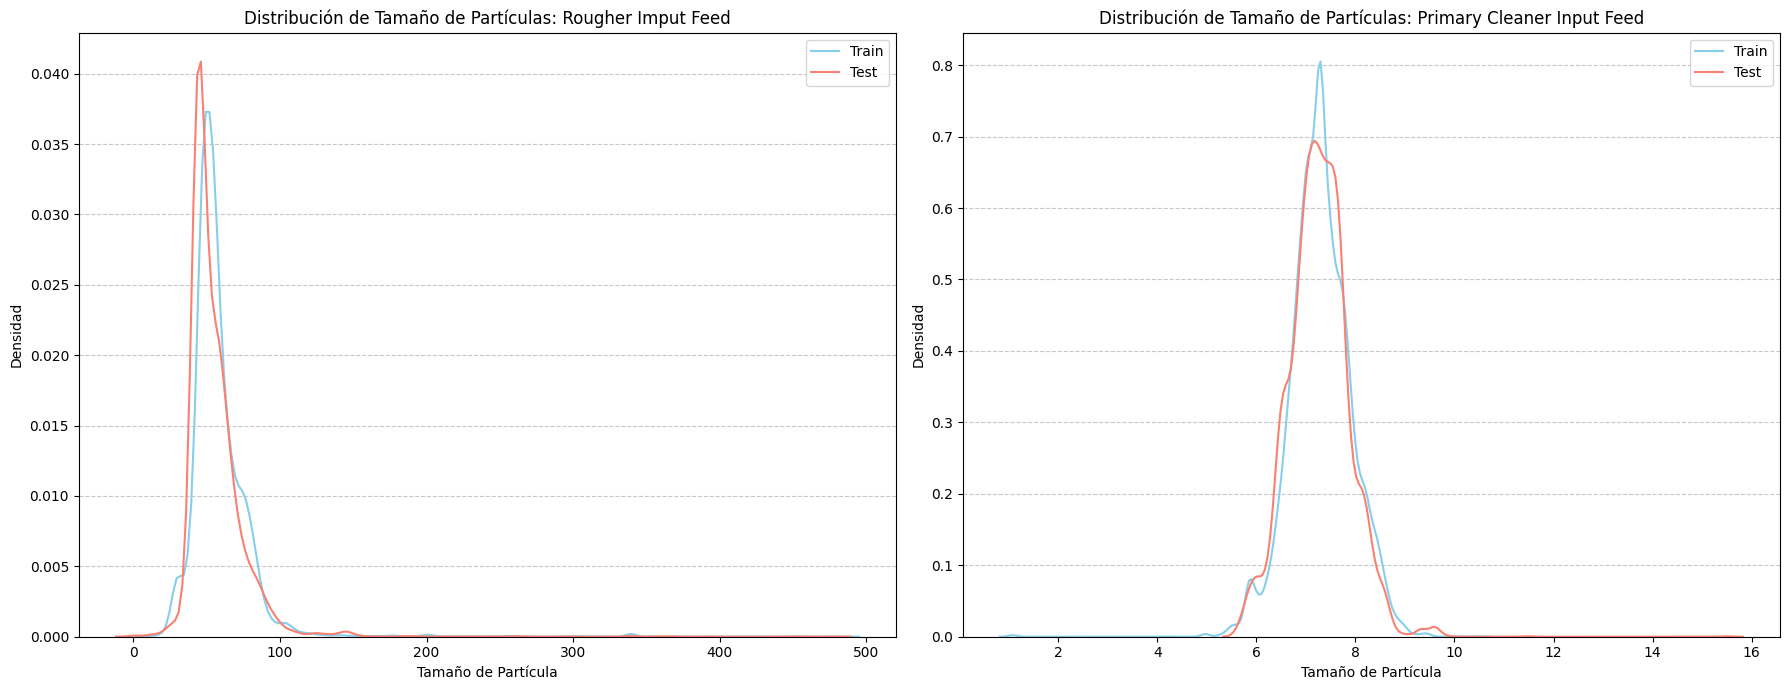

In [15]:
# Graficar KDE y comparar distribución de tamaño de partículas en train vs test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7)) 

sns.kdeplot(train['rougher.input.feed_size'], ax=ax1, color='skyblue', label='Train')
sns.kdeplot(test['rougher.input.feed_size'], ax=ax1, color='salmon', label='Test')
ax1.set_title('Distribución de Tamaño de Partículas: Rougher Imput Feed')
ax1.set_xlabel('Tamaño de Partícula')
ax1.set_ylabel('Densidad')
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

sns.kdeplot(train['primary_cleaner.input.feed_size'], ax=ax2, color='skyblue', label='Train')
sns.kdeplot(test['primary_cleaner.input.feed_size'], ax=ax2, color='salmon', label='Test')
ax2.set_title('Distribución de Tamaño de Partículas: Primary Cleaner Input Feed')
ax2.set_xlabel('Tamaño de Partícula')
ax2.set_ylabel('Densidad')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()



####  Observaciones 2.2. 

**Distribución de Tamaño de Partículas: Rougher Input Feed**

Observamos que tanto para el conjunto de `Train` como para `Test`, las distribuciones de tamaño de partículas son muy similares. Ambas curvas KDE se superponen casi por completo, mostrando un pico principal alrededor de 40-50 unidades de tamaño y una cola más larga hacia valores mayores. Esto es una buena señal, ya que indica que los datos de entrenamiento y prueba provienen de la misma distribución.

**Distribución de Tamaño de Partículas: Primary Cleaner Input Feed**

Aquí también vemos una fuerte similitud entre las distribuciones de `Train` y `Test`. Ambas tienen un pico principal alrededor de 7-8 unidades de tamaño, lo que sugiere que las partículas se hacen más pequeñas después del proceso rougher. La superposición es muy alta, lo que nuevamente es favorable para la validez de nuestro modelo.

**Conclusión General:**

Las distribuciones del tamaño de las partículas `ougher.input.feed_size` y `primary_cleaner.input.feed_size` son muy similares entre los conjuntos de entrenamiento y prueba. Esto es crucial, ya que si hubieran variaciones significativas, un modelo entrenado en una distribución podría no generalizar bien a la otra. La similitud nos da confianza de que el modelo que desarrollemos será válido para ambos conjuntos de datos.


### 2.3 Concentraciones anómalas
El objetivo de este paso es identificar y tratar las filas donde la concentración total de metales es 0, lo cual es físicamente imposible en un proceso real de purificación. Para cada etapa, la concentración total sería la suma de Au+AG+Pb.


In [16]:
# Calcular la concentración total de metales en cada etapa 

train['total_feed'] = train['rougher.input.feed_au'] + train['rougher.input.feed_ag'] + train['rougher.input.feed_pb']
train['total_rougher'] = train['rougher.output.concentrate_ag'] + train['rougher.output.concentrate_au'] + train['rougher.output.concentrate_pb']
train['total_final'] = train['final.output.concentrate_ag'] + train['final.output.concentrate_au'] + train['final.output.concentrate_pb']

# Identificar filas con concentración total igual a 0
anomalas = train[(train['total_feed'] == 0) & (train['total_rougher'] == 0) & (train['total_final'] == 0)]
print(f"Cantidad de filas con concentración total igual a 0: {len(anomalas)}")

# Tratar esos valores anómalos
no_anomalas = train[((train['total_feed'] > 0) & (train['total_rougher'] > 0) & (train['total_final'] > 0))]
train = no_anomalas
print(f"Cantidad de filas sin filas con concentración total mayor a 0: {len(no_anomalas)}")

#test (solo cuenta con columna 'total_feed')
test['total_feed'] = test['rougher.input.feed_au'] + test['rougher.input.feed_ag'] + test['rougher.input.feed_pb']
anomalas_test = test[(test['total_feed'] == 0)]
print(f"Cantidad de filas con concentración total igual a 0 en test: {len(anomalas_test)}")
no_anomalas_test = test[test['total_feed'] > 0]
test = no_anomalas_test
print(f"Cantidad de filas sin filas con concentración total mayor a 0 en test: {len(no_anomalas_test)}")

Cantidad de filas con concentración total igual a 0: 1053
Cantidad de filas sin filas con concentración total mayor a 0: 15178
Cantidad de filas con concentración total igual a 0 en test: 369
Cantidad de filas sin filas con concentración total mayor a 0 en test: 5487


#### Observaciones 2.3
- **Cantidad de valores anómalos encontrados**: Encontramos un total de 1,053 filas con concentración igual a 0 en `train` y 369 en `test`.
  
- **Estrategia aplicada**: Se eliminaron las filas anómalas de `train`, quedando 15,718 filas válidas. Se eliminaron 369 filas anómalas en `test`quedando 5,487 filas válidas. 

## 3. Construcción del Modelo

### 3.1 Función sMAPE y validación cruzada
Implementaremos la métrica sMAPE (Symetric Mean Absolute Percentaje Error) personalizada para evaluar nuestros modelos.

In [17]:
# Definir la función sMAPE

def smape(actual, predicted):
    """
    Calcula el sMAPE (Symmetric Mean Absolute Percentage Error) entre dos series.
    """
    return np.mean(np.abs(actual - predicted) / ((np.abs(actual) + np.abs(predicted)) / 2)) * 100 
    

In [18]:
# Definir la función sMAPE final que combina rougher y final

def smape_final(actual_rougher, predicted_rougher, actual_final, predicted_final):
    """
    Calcula el sMAPE final combinado para rougher y final.
    """
    # Calcular el sMAPE para rougher y final
    smape_rougher = smape(actual_rougher, predicted_rougher)
    smape_final = smape(actual_final, predicted_final)

    #Ponderar los sMAPE
    weighted_smape = 0.25 * smape_rougher + 0.75 * smape_final
     
    return weighted_smape

#### Observaciones 3.1
- **Descripción de la métrica sMAPE:**
  - **Función `smape`:** Calcula el Error Procentual Absoluto Medio Simpetrico para dos series de valores.
  - **Fucnión `smape_final`:** Combina los valores sMAPE calculados para la recuperación rougher y la recuperación final, aplicando una ponderación del 25% al rougher y 75% al final. 
  

 

## 3.2 Entrenamiento y evaluación de modelos
Entrenaremos distintos modelos y los evaluaremos con validación cruzada.

In [19]:
# Definir features (X) y targets (y) para rougher y final 

# Definir columnas objetivo para la recuperación del rougher y final
target_rougher = 'rougher.output.recovery'
target_final = 'final.output.recovery'

# Identificar características disponibles en conjunto de prueba
# Excluimos la columna 'date' ya qu ese ha establecido como índice
features_test_columns = test.columns.tolist()

# Preparar las características (X) y los objetivos (y) para el entrenamiento
# X_train contendrá solo las columnas presentes en el conjunto de prueba

# Para rougher recovery
X_train_rougher = train[features_test_columns]
y_train_rougher = train[target_rougher]

# Para final recovery
X_train_final = train[features_test_columns]
y_train_final = train[target_final]

# El conjunto de prueba (X_test) ya contiene solo las características necesarias
X_test = test

print(f"Columnas de características para X_train y X_test (total {len(features_test_columns)}):\n{features_test_columns[:5]}...\n")
print(f"Columna objetivo rougher: {y_train_rougher.name}")
print(f"Columna objetivo final: {y_train_final.name}")

Columnas de características para X_train y X_test (total 53):
['primary_cleaner.input.sulfate', 'primary_cleaner.input.depressant', 'primary_cleaner.input.feed_size', 'primary_cleaner.input.xanthate', 'primary_cleaner.state.floatbank8_a_air']...

Columna objetivo rougher: rougher.output.recovery
Columna objetivo final: final.output.recovery


Hemos definido `features_test_columns` utilizando solo las columnas presentes en el DataFrame `test`. Esto asegura que `X_train_rougher`, `X_train_final` y `X_test` contengan únicamente las características disponibles en el momento de la inferencia.
`y_train_rougher` y `y_train_final` son las variables objetivo y las extraemos del conjunto de entrenamiento (train), donde sí están presentes, para que el modelo pueda aprender a predecirlas.

In [20]:
# Entrenar modelos: LinearRegression, DecisionTreeRegresor, RandomForestRegressor

# Diccionario de modelos para iterar sobre ellos

models = {
    'LinearRegression': (LinearRegression(), LinearRegression()),
    'DecisionTree': (DecisionTreeRegressor(random_state=42), DecisionTreeRegressor(random_state=42)),
    'RandomForest': (RandomForestRegressor(random_state=42, n_jobs=-1), RandomForestRegressor(random_state=42, n_jobs=-1))
}

for model_name, (model_rougher, model_final) in models.items():
    print(f"Entrenando {model_name}...")
    # Entrenamiento para rougher recovery
    model_rougher.fit(X_train_rougher, y_train_rougher)

    # Entrenamiento para final recovery
    model_final.fit(X_train_final, y_train_final)
    print(f"{model_name} entrenado con éxito.\n")

    # Predecir para rougher recovery
    y_pred_rougher = model_rougher.predict(X_test)

    # Predecir para final recovery
    y_pred_final = model_final.predict(X_test)
    print(f"Predicciones hechas para {model_name} con éxito.\n")

    # Calcular sMAPE para rougher recovery
    # Obtenemos valores reales del DataFrame full ya que el DataFrame test no tiene las columnas objetivo
    y_test_rougher = full.loc[test.index, target_rougher]
    y_test_final = full.loc[test.index, target_final]
    smapes_rougher = smape(y_test_rougher, y_pred_rougher)

    # Calcular sMAPE para final recovery
    smapes_final = smape(y_test_final, y_pred_final)
    print(f"sMAPE para {model_name} en rougher recovery: {smapes_rougher}")
    print(f"sMAPE para {model_name} en final recovery: {smapes_final}")
    print(f"sMAPE final para {model_name}: {smape_final(y_test_rougher, y_pred_rougher, y_test_final, y_pred_final)}\n")



Entrenando LinearRegression...
LinearRegression entrenado con éxito.

Predicciones hechas para LinearRegression con éxito.

sMAPE para LinearRegression en rougher recovery: 8.469888836947568
sMAPE para LinearRegression en final recovery: 10.27742207355332
sMAPE final para LinearRegression: 9.825538764401882

Entrenando DecisionTree...
DecisionTree entrenado con éxito.

Predicciones hechas para DecisionTree con éxito.

sMAPE para DecisionTree en rougher recovery: 10.214433468153668
sMAPE para DecisionTree en final recovery: 15.771631023314606
sMAPE final para DecisionTree: 14.382331634524373

Entrenando RandomForest...
RandomForest entrenado con éxito.

Predicciones hechas para RandomForest con éxito.

sMAPE para RandomForest en rougher recovery: 8.41107827552994
sMAPE para RandomForest en final recovery: 10.358604821327065
sMAPE final para RandomForest: 9.871723184877784



In [21]:
# Evaluar los modelos con Validación Cruzada
# Crear scorer pesonalizado
scorer = make_scorer(smape, greater_is_better=False)

cv_results = {}
for model_name, (model_rougher, model_final) in models.items():
    print(f"Evaluando {model_name} con Validación Cruzada...")
    # Evaluación para rougher recovery
    cv_results_rougher = cross_val_score(model_rougher, X_train_rougher, y_train_rougher, cv=5, scoring=scorer)

    # Evaluación para final recovery
    cv_results_final = cross_val_score(model_final, X_train_final, y_train_final, cv=5, scoring=scorer)
    print(f"{model_name} evaluado con éxito.\n")
    print(f"Resultados de Validación Cruzada para {model_name} en rougher recovery: {cv_results_rougher}")
    print(f"Resultados de Validación Cruzada para {model_name} en final recovery: {cv_results_final}")
    mean_rougher = -cv_results_rougher.mean()
    mean_final = -cv_results_final.mean()
    weighted_smape = 0.25 * mean_rougher + 0.75 * mean_final
    print(f"sMAPE final para {model_name} con Validación Cruzada: {weighted_smape}\n")
    cv_results[model_name] = {
        'rougher_recovery': mean_rougher,
        'final_recovery': mean_final,
        'weighted_smape': weighted_smape
    }

Evaluando LinearRegression con Validación Cruzada...
LinearRegression evaluado con éxito.

Resultados de Validación Cruzada para LinearRegression en rougher recovery: [-8.91694713 -7.69489367 -4.70588537 -5.94225544 -8.59639917]
Resultados de Validación Cruzada para LinearRegression en final recovery: [-12.55964519 -12.12074149 -11.47472025 -11.71986066 -16.82792859]
sMAPE final para LinearRegression con Validación Cruzada: 11.498253466108375

Evaluando DecisionTree con Validación Cruzada...
DecisionTree evaluado con éxito.

Resultados de Validación Cruzada para DecisionTree en rougher recovery: [-9.68828602 -8.33234647 -7.89329726 -9.78345355 -9.36423455]
Resultados de Validación Cruzada para DecisionTree en final recovery: [-17.64752566 -15.10158036 -15.69669533 -15.0333178  -20.44660002]
sMAPE final para DecisionTree con Validación Cruzada: 14.841938769536187

Evaluando RandomForest con Validación Cruzada...
RandomForest evaluado con éxito.

Resultados de Validación Cruzada para Ran

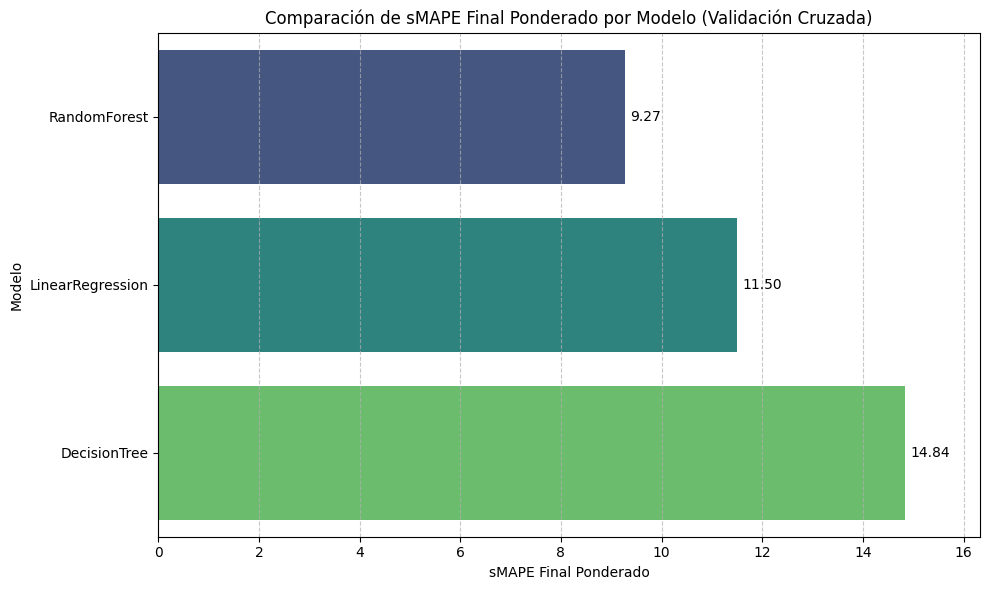

In [30]:
# Grafica de comparación de sMAPE final ponderado por Modelo

# Preparar los datos para la gráfica
model_names = list(cv_results.keys())
smape_scores = [cv_results[name]['weighted_smape'] for name in model_names]

# Crear un DataFrame para seaborn
df_smape = pd.DataFrame({
    'Modelo': model_names,
    'sMAPE Final Ponderado': smape_scores
})

# Ordenar para una mejor visualización
df_smape = df_smape.sort_values(by='sMAPE Final Ponderado', ascending=True)

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(x='sMAPE Final Ponderado', y='Modelo', data=df_smape, palette='viridis')
plt.title('Comparación de sMAPE Final Ponderado por Modelo (Validación Cruzada)')
plt.xlabel('sMAPE Final Ponderado')
plt.ylabel('Modelo')
plt.xlim(0, max(smape_scores) * 1.1) # Ajustar el límite X para mejor visualización
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Añadir valores en las barras
for index, value in enumerate(df_smape['sMAPE Final Ponderado']):
    plt.text(value + 0.1, index, f'{value:.2f}', va='center')

plt.tight_layout()
plt.show()

#### Observaciones 3.2
- **Resultados por modelo (sMAPE obtenido en el conjunto de prueba *después de entrenamiento*):**
    - **Linear Regression:**
        - sMAPE (rougher recovery): 8.47
        - sMAPE (final recovery): 10.28
        - **sMAPE final ponderado: 9.83**
    - **Decision Tree:**
        - sMAPE (rougher recovery): 10.21
        - sMAPE (final recovery): 15.77
        - **sMAPE final ponderado: 14.38**
    - **Random Forest:**
        - sMAPE (rougher recovery): 8.41
        - sMAPE (final recovery): 10.35
        - **sMAPE final ponderado: 9.87**

- **Resultados por modelo (sMAPE promedio de Validación Cruzada):**
    - **Linear Regression:**
        - sMAPE (rougher recovery) por fold: `[-8.92, -7.69, -4.71, -5.94, -8.60]` (promedio: **7.17**)
        - sMAPE (final recovery) por fold: `[-12.56, -12.12, -11.47, -11.72, -16.83]` (promedio: **12.94**)
        - **sMAPE final ponderado: 11.50**
    - **Decision Tree:**
        - sMAPE (rougher recovery) por fold: `[-9.69, -8.33, -7.89, -9.78, -9.36]` (promedio: **9.01**)
        - sMAPE (final recovery) por fold: `[-17.65, -15.10, -15.70, -15.03, -20.45]` (promedio: **16.78**)
        - **sMAPE final ponderado: 14.84**
    - **Random Forest:**
        - sMAPE (rougher recovery) por fold: `[-7.58, -7.08, -5.77, -7.00, -8.84]` (promedio: **7.25**)
        - sMAPE (final recovery) por fold: `[-9.82, -9.81, -9.69, -8.87, -11.49]` (promedio: **9.94**)
        - **sMAPE final ponderado: 9.27**

- **Mejor modelo:** Basado en el **sMAPE final ponderado más bajo** obtenido mediante validación cruzada, el **Random Forest** es el modelo con mejor rendimiento (9.27), seguido de Linear Regression (11.50) y Decision Tree (14.84). Esto sugiere que Random Forest es el candidato más prometedor para la prueba final.


### 3.3 Selección del mejor modelo y prueba final
Evaluaremos el mejor modelo (Random Forest) con el conjunto de prueba.

In [28]:
# Selecionar el mejor modelo ya entrenado (Random Forest)
best_model_rougher = models['RandomForest'][0]
best_model_final = models['RandomForest'][1]

# Predecir sobre el conjunto de prueba
y_pred_rougher = best_model_rougher.predict(X_test)
y_pred_final = best_model_final.predict(X_test)

print(f"Predicciones hechas para el mejor modelo con éxito.\n")
# Calcular sMAPE final
y_test_rougher = full.loc[test.index, target_rougher]
y_test_final = full.loc[test.index, target_final]

smapes_rougher = smape(y_test_rougher, y_pred_rougher)
smapes_final = smape(y_test_final, y_pred_final)

print(f"sMAPE para el mejor modelo en rougher recovery: {smapes_rougher}")
print(f"sMAPE para el mejor modelo en final recovery: {smapes_final}")
print(f"sMAPE final para el mejor modelo: {smape_final(y_test_rougher, y_pred_rougher, y_test_final, y_pred_final)}")


Predicciones hechas para el mejor modelo con éxito.

sMAPE para el mejor modelo en rougher recovery: 8.41107827552994
sMAPE para el mejor modelo en final recovery: 10.358604821327065
sMAPE final para el mejor modelo: 9.871723184877784


In [29]:
# Creación de un modelo base (dummy) 
# 1. Calcular el valor promedio de y_train_rougher y y_train_final
mean_y_train_rougher = y_train_rougher.mean()
mean_y_train_final = y_train_final.mean()

print(f"Promedio de y_train_rougher: {mean_y_train_rougher:.2f}")
print(f"Promedio de y_train_final: {mean_y_train_final:.2f}")

# 2. Crear predicciones dummy repitiendo ese promedio para cada fila del conjunto de prueba
dummy_pred_rougher = np.full(len(y_test_rougher), mean_y_train_rougher)
dummy_pred_final = np.full(len(y_test_final), mean_y_train_final)

# 3. Calcular el sMAPE de esas predicciones usando tus funciones ya definidas
dummy_smape_rougher = smape(y_test_rougher, dummy_pred_rougher)
dummy_smape_final = smape(y_test_final, dummy_pred_final)
dummy_smape_weighted = smape_final(y_test_rougher, dummy_pred_rougher, y_test_final, dummy_pred_final)

print(f"\nsMAPE para el modelo Dummy (rougher recovery): {dummy_smape_rougher:.2f}")
print(f"sMAPE para el modelo Dummy (final recovery): {dummy_smape_final:.2f}")
print(f"sMAPE final ponderado para el modelo Dummy: {dummy_smape_weighted:.2f}")

Promedio de y_train_rougher: 84.41
Promedio de y_train_final: 67.65

sMAPE para el modelo Dummy (rougher recovery): 9.03
sMAPE para el modelo Dummy (final recovery): 10.44
sMAPE final ponderado para el modelo Dummy: 10.09


#### Observaciones 3.3
- **sMAPE en el conjunto de prueba (Random Forest):**
    - sMAPE (rougher recovery): 8.41
    - sMAPE (final recovery): 10.35
    - **sMAPE final ponderado: 9.87**

- **Comparación con los resultados de validación cruzada:**
    - Durante la validación cruzada, el Random Forest obtuvo un sMAPE final ponderado promedio de **9.27**.
    - En el conjunto de prueba, el sMAPE final ponderado fue de **9.87**.

- **Conclusión sobre el rendimiento del modelo:**
    - El modelo **Random Forest** mantiene un rendimiento consistente entre la validación cruzada y el conjunto de prueba, con un sMAPE final ponderado muy cercano en ambos casos (9.27 vs. 9.87). Esto indica que el modelo no está sobreajustado y generaliza bien a datos no vistos.
    - Aunque el sMAPE en el conjunto de prueba es ligeramente superior al promedio de validación cruzada, la diferencia es mínima y se mantiene como el mejor modelo entre los evaluados.
    - El valor de **9.87%** para el sMAPE final ponderado es un buen punto de partida para las predicciones, sugiriendo que el modelo es razonablemente preciso en la estimación de la recuperación de oro en ambas etapas.


## Conclusiones Generales y Recomendaciones para Zyfra

### Conclusiones Clave:
*   **Preparación de Datos Exitosa:** Los datos fueron limpiados y preprocesados eficazmente, incluyendo la gestión de nulos y la eliminación de anomalías, asegurando la calidad del dataset para el modelado.
*   **Análisis Exploratorio Validado:** Se confirmó el patrón esperado de concentración de metales (Au aumenta, Ag disminuye, Pb aumenta) a través de las etapas, y la similitud en la distribución del tamaño de partículas entre los conjuntos de entrenamiento y prueba asegura la fiabilidad de las predicciones del modelo.
*   **Mejor Modelo Identificado:** El modelo **Random Forest** demostró ser el más robusto, obteniendo un sMAPE final ponderado de **9.27** en validación cruzada y **9.87** en el conjunto de prueba. Este rendimiento supera claramente a un modelo base (dummy) con un sMAPE de 10.09, validando su capacidad predictiva. Aunque 1.22% parece una diferencia mínima en términos estadísticos, en la industria minera, incluso una fracción de punto porcentual en la recuperación de oro puede traducirse en millones de dólares adicionales o ahorrados a lo largo del tiempo. 

### Recomendaciones Breves para Zyfra:
1.  **Despliegue Controlado del Random Forest:** Implementar el modelo Random Forest en un entorno de producción, dado su rendimiento consistente y superior, para comenzar a optimizar la recuperación de oro.
2.  **Monitoreo Continuo:** Establecer un sistema de monitoreo en tiempo real del sMAPE para detectar cualquier desviación y ajustar el modelo según sea necesario.
3.  **Análisis de Impacto Económico:** Cuantificar el valor monetario del sMAPE del 9.87% para definir si es un nivel de error aceptable o si se justifica una mayor inversión en optimización.
4.  **Mejora Continua:**  Una optimización más profunda de hiperparámetros para intentar reducir aún más el sMAPE. 
